# 01 · Exploring the SisFall "Three Classes" dataset

Goal: understand what is in `~/Downloads/archive (2).zip` before building a fall detector.

**What we know going in**

- [SisFall](https://www.mdpi.com/1424-8220/17/1/198) (Sucerquia et al., 2017): 38 participants (23 young, 15 elderly) wearing a
  waist-mounted device (ADXL345 + ITG3200 + MMA8451Q) at **200 Hz**. 19 ADL types and 15 fall types (F01–F15).
- This archive is *not* the raw SisFall release. It is a preprocessed derivative with no README: headerless binaries
  `x_{train,val,test}_3`, `y_{train,val,test}_3` and `weights_3.txt`.

**What this notebook works out**

1. File layout, shapes and class balance
2. Units and sensor orientation
3. What the three classes look like
4. Temporal structure (window stride, label sequences)
5. How separable the classes are with simple features
6. What's missing for our goals (fall *type*, matching our LSM6DSOX hardware)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ysafetyml.data import CHANNELS, SAMPLE_HZ, SPLITS, WINDOW, load_all, load_class_weights

sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(0)
data = load_all()

## 1. Layout and class balance

The byte patterns give the layout: `x` is float32 (n, 256, 6), and `y` is one-hot uint8 (n, 3). `load_split` checks that the
file sizes match this exactly.

In [3]:
summary = pd.DataFrame(
    {
        s: {
            "windows": len(d),
            "x shape": d.x.shape,
            **{f"class {c}": int((d.y == c).sum()) for c in range(3)},
        }
        for s, d in data.items()
    }
).T
for c in range(3):
    summary[f"class {c} %"] = (summary[f"class {c}"] / summary["windows"] * 100).astype(float).round(2)
summary

,windows,x shape,class 0,class 1,class 2,class 0 %,class 1 %,class 2 %
train,77871,"(77871, 256, 6)",74937,696,2238,96.23,0.89,2.87
val,20233,"(20233, 256, 6)",19463,221,549,96.19,1.09,2.71
test,18884,"(18884, 256, 6)",18180,157,547,96.27,0.83,2.90


In [4]:
counts = np.bincount(data["train"].y, minlength=3)
w_file = load_class_weights()
w_from_counts = counts.max() / counts
pd.DataFrame({"train count": counts, "max/count": w_from_counts.round(2), "weights_3.txt (as listed)": w_file.round(2)},
             index=[f"class {c}" for c in range(3)])

,train count,max/count,weights_3.txt (as listed)
class 0,74937,1.00,33.48
class 1,696,107.67,107.67
class 2,2238,33.48,1.00


`weights_3.txt` is `max_count / count`, but listed in **reverse class order** (class 2, 1, 0). If we use it, reverse it
first, or just recompute weights from the counts.

The imbalance is severe: class 0 is about 96% of windows. Plain accuracy is useless here; we'll judge models on per-class recall,
precision and PR-AUC.

## 2. Units and orientation

In [5]:
x_tr = data["train"].x
sub = np.asarray(x_tr[rng.choice(len(x_tr), 4000, replace=False)])  # (4000, 256, 6)
flat = sub.reshape(-1, 6)
stats = pd.DataFrame(flat, columns=CHANNELS).describe(percentiles=[0.01, 0.5, 0.99]).T
stats

,count,mean,std,min,1%,50%,99%,max
ax,1024000.0,0.001219,0.087542,-1.163847,-0.234476,0.003185,0.236253,1.215681
ay,1024000.0,-0.161922,0.126844,-1.187193,-0.500449,-0.208879,0.118564,0.599173
az,1024000.0,-0.026964,0.105958,-1.127360,-0.257932,-0.030543,0.223866,1.021689
gx,1024000.0,-0.001124,0.056948,-1.103160,-0.186351,-0.001451,0.167248,1.888113
gy,1024000.0,0.004841,0.066742,-1.919259,-0.192611,0.003808,0.204035,1.694872
gz,1024000.0,-0.000464,0.052969,-1.726382,-0.144887,-0.000750,0.144888,1.740308


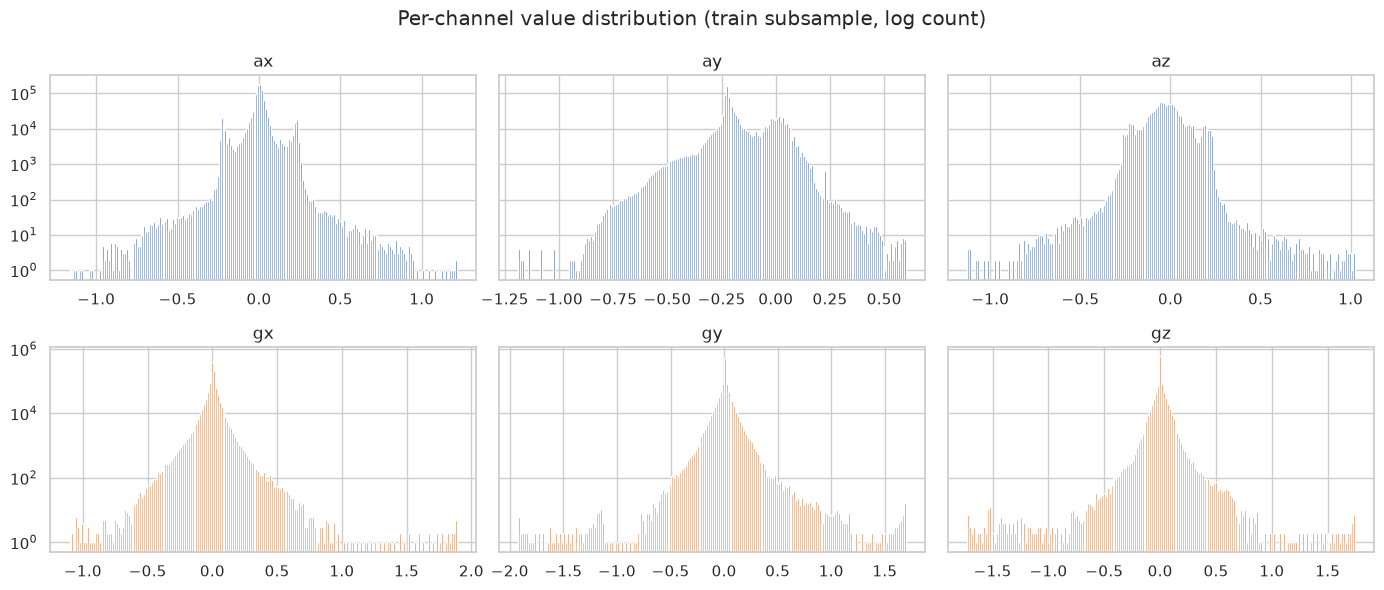

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey="row")
for i, (ax, name) in enumerate(zip(axes.flat, CHANNELS)):
    ax.hist(flat[:, i], bins=200, log=True, color="C0" if i < 3 else "C1")
    ax.set_title(name)
fig.suptitle("Per-channel value distribution (train subsample, log count)")
fig.tight_layout()

In [7]:
acc_mag = np.linalg.norm(flat[:, :3], axis=1)
gyro_mag = np.linalg.norm(flat[:, 3:], axis=1)
still = gyro_mag < np.percentile(gyro_mag, 20)  # quiet samples, ~ only gravity
g_unit = np.median(acc_mag[still])
print(f"|accel| when still: median {g_unit:.4f} -> 1 g ≈ {g_unit:.4f} units, scale factor ≈ {1 / g_unit:.2f}")
print("mean accel direction when still:", (flat[still, :3].mean(0) / g_unit).round(3))

|accel| when still: median 0.2313 -> 1 g ≈ 0.2313 units, scale factor ≈ 4.32
mean accel direction when still: [ 0.011 -0.457 -0.078]


Values are **scaled**, not in g. With the sensor still, |accel| is roughly constant, so that value is 1 g; we use it to
convert to g. Gravity sits mostly on **−y**, which matches SisFall's waist mount (y is vertical).

For our LSM6DSOX recordings to be comparable, we will have to apply the same scale and match the axis orientation. Gyro scaling
is still unknown. The preprocessing probably divided both sensors by a constant, which we can estimate later by matching rotation
rates to the raw dataset.

## 3. What each class looks like

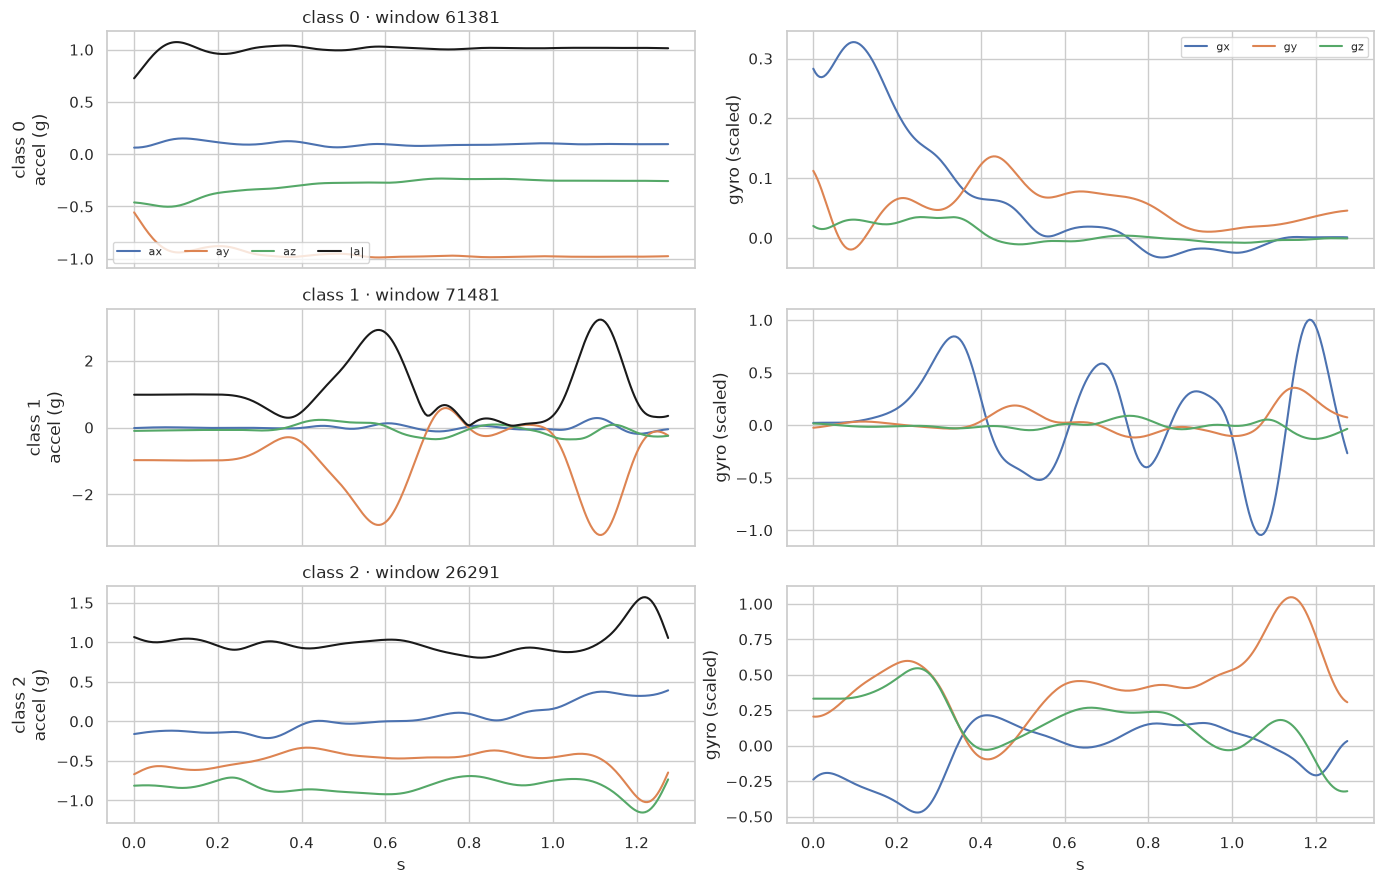

In [10]:
t = np.arange(WINDOW) / SAMPLE_HZ
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
d = data["train"]
for c in range(3):
    i = rng.choice(np.flatnonzero(d.y == c))
    w = np.asarray(d.x[i]) / g_unit
    for k in range(3):
        axes[c, 0].plot(t, w[:, k], label=CHANNELS[k])
        axes[c, 1].plot(t, w[:, 3 + k], label=CHANNELS[3 + k])
    axes[c, 0].plot(t, np.linalg.norm(w[:, :3], axis=1), "k", lw=1.5, label="|a|")
    axes[c, 0].set_ylabel(f"class {c}\naccel (g)")
    axes[c, 1].set_ylabel("gyro (scaled)")
    axes[c, 0].set_title(f"class {c} · window {i}")
axes[0, 0].legend(ncol=4, fontsize=8)
axes[0, 1].legend(ncol=3, fontsize=8)
axes[-1, 0].set_xlabel("s")
axes[-1, 1].set_xlabel("s")
fig.tight_layout()

In [11]:
def window_features(x: np.ndarray, g: float) -> pd.DataFrame:
    a = np.linalg.norm(x[..., :3], axis=-1) / g
    w = np.linalg.norm(x[..., 3:], axis=-1)
    return pd.DataFrame({
        "peak |a| (g)": a.max(1),
        "min |a| (g)": a.min(1),
        "std |a| (g)": a.std(1),
        "peak |ω|": w.max(1),
        "peak position (s)": a.argmax(1) / SAMPLE_HZ,
        "Δ tilt (end − start, °)": np.degrees(np.arccos(np.clip(
            np.einsum("ij,ij->i", x[:, :32, :3].mean(1), x[:, -32:, :3].mean(1))
            / (np.linalg.norm(x[:, :32, :3].mean(1), axis=1) * np.linalg.norm(x[:, -32:, :3].mean(1), axis=1)), -1, 1))),
    })

def features_for(split: str, chunk: int = 8192) -> pd.DataFrame:
    d = data[split]
    parts = [window_features(np.asarray(d.x[i:i + chunk]), g_unit) for i in range(0, len(d), chunk)]
    f = pd.concat(parts, ignore_index=True)
    f["class"] = d.y
    return f

feats = {s: features_for(s) for s in SPLITS}
feats["train"].groupby("class").median().round(3)

,peak |a| (g),min |a| (g),std |a| (g),peak |ω|,peak position (s),"Δ tilt (end − start, °)"
class,,,,,,
0,1.100,0.921,0.030,0.085,0.565,4.675000
1,2.697,0.162,0.641,0.249,0.695,15.456000
2,3.240,0.345,0.607,0.617,0.800,84.750999


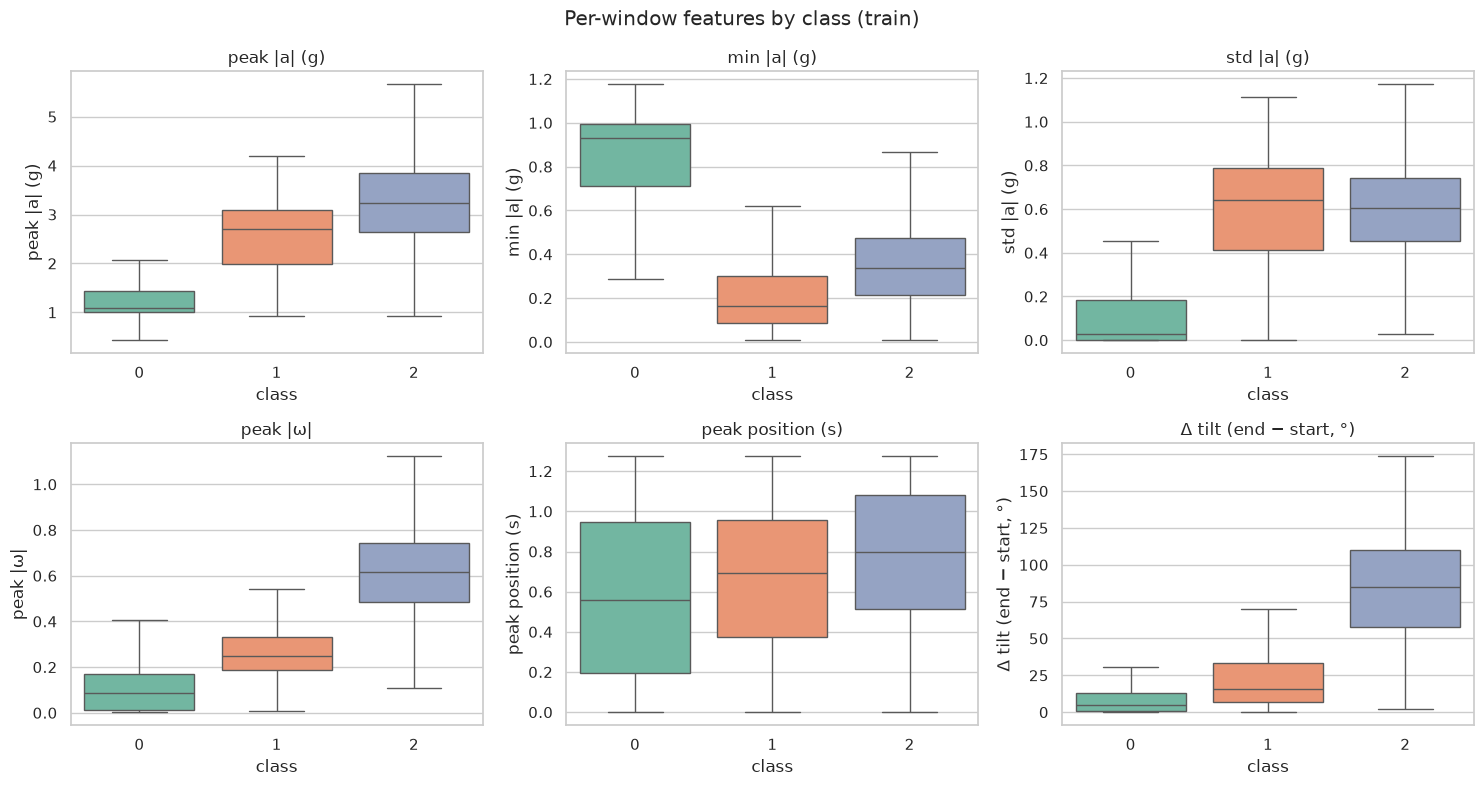

In [ ]:
cols = [c for c in feats["train"].columns if c != "class"]
plot_df = pd.concat([g.sample(min(len(g), 2000), random_state=0) for _, g in feats["train"].groupby("class")])
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cols):
    sns.boxplot(data=plot_df, x="class", y=col, ax=ax, showfliers=False, hue="class", palette="Set2", legend=False)
    ax.set_title(col)
fig.suptitle("Per-window features by class (train)")
fig.tight_layout()

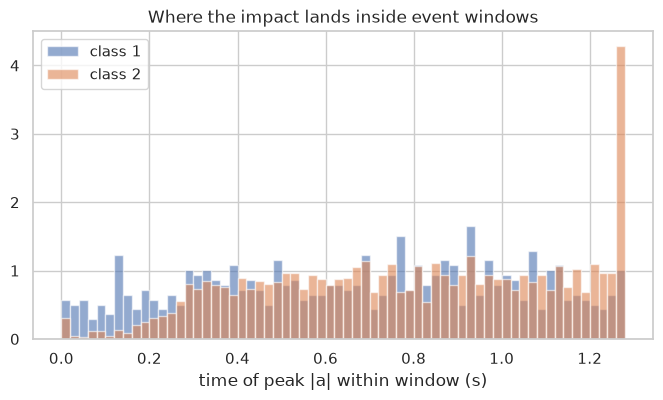

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
for c in (1, 2):
    sel = feats["train"].query("`class` == @c")
    ax.hist(sel["peak position (s)"], bins=64, range=(0, WINDOW / SAMPLE_HZ), alpha=0.6, label=f"class {c}", density=True)
ax.set_xlabel("time of peak |a| within window (s)")
ax.set_title("Where the impact lands inside event windows")
ax.legend();

## 4. Temporal structure

In [ ]:
def overlap_fraction(x, shift: int, n: int = 3000) -> float:
    n = min(n, len(x) - 1)
    a = np.asarray(x[:n + 1])
    return float(np.mean([np.allclose(a[i, shift:], a[i + 1, :WINDOW - shift]) for i in range(n)]))

rows = []
for s, d in data.items():
    rows.append({"split": s, **{f"overlap@{k}": overlap_fraction(d.x, k) for k in (64, 128, 192)}})
pd.DataFrame(rows).set_index("split").round(3)

,overlap@64,overlap@128,overlap@192
split,,,
train,0.0,0.000,0.000
val,0.0,0.000,0.000
test,0.0,0.964,0.037


In [ ]:
def runs(y):
    edges = np.flatnonzero(np.diff(y)) + 1
    starts, ends = np.r_[0, edges], np.r_[edges, len(y)]
    return pd.DataFrame({"class": y[starts], "start": starts, "length": ends - starts})

rows = []
for s, d in data.items():
    r = runs(d.y)
    trans = pd.crosstab(d.y[:-1], d.y[1:])
    for c in range(3):
        rc = r[r["class"] == c]["length"]
        rows.append({"split": s, "class": c, "runs": len(rc), "median len": rc.median(), "max len": rc.max()})
pd.DataFrame(rows).set_index(["split", "class"])

runs  median len  max len
split class                           
train 0      2844        18.0      231
      1       692         1.0        2
      2      2186         1.0        2
val   0       746        19.0      177
      1       221         1.0        1
      2       536         1.0        3
test  0       383        22.0     1636
      1        86         2.0        3
      2       303         2.0        2

In [ ]:
pd.crosstab(data['train'].y[:-1], data['train'].y[1:], rownames=['from'], colnames=['to'])

to,0,1,2
from,,,
0,72093,674,2169
1,675,4,17
2,2168,18,52


- Classes 1 and 2 show up as **short events of 1–3 windows** inside long class-0 stretches. They almost never follow each other
  directly; each has its own `0 → event → 0` pattern.
- In **test**, consecutive windows overlap by 50% (stride 128 = 0.64 s), so the test split can be stitched back into continuous
  recordings. Train and val don't overlap that way; they look shuffled or chunked.

Below, consecutive test windows are stitched into one continuous stream and plotted around a few events.

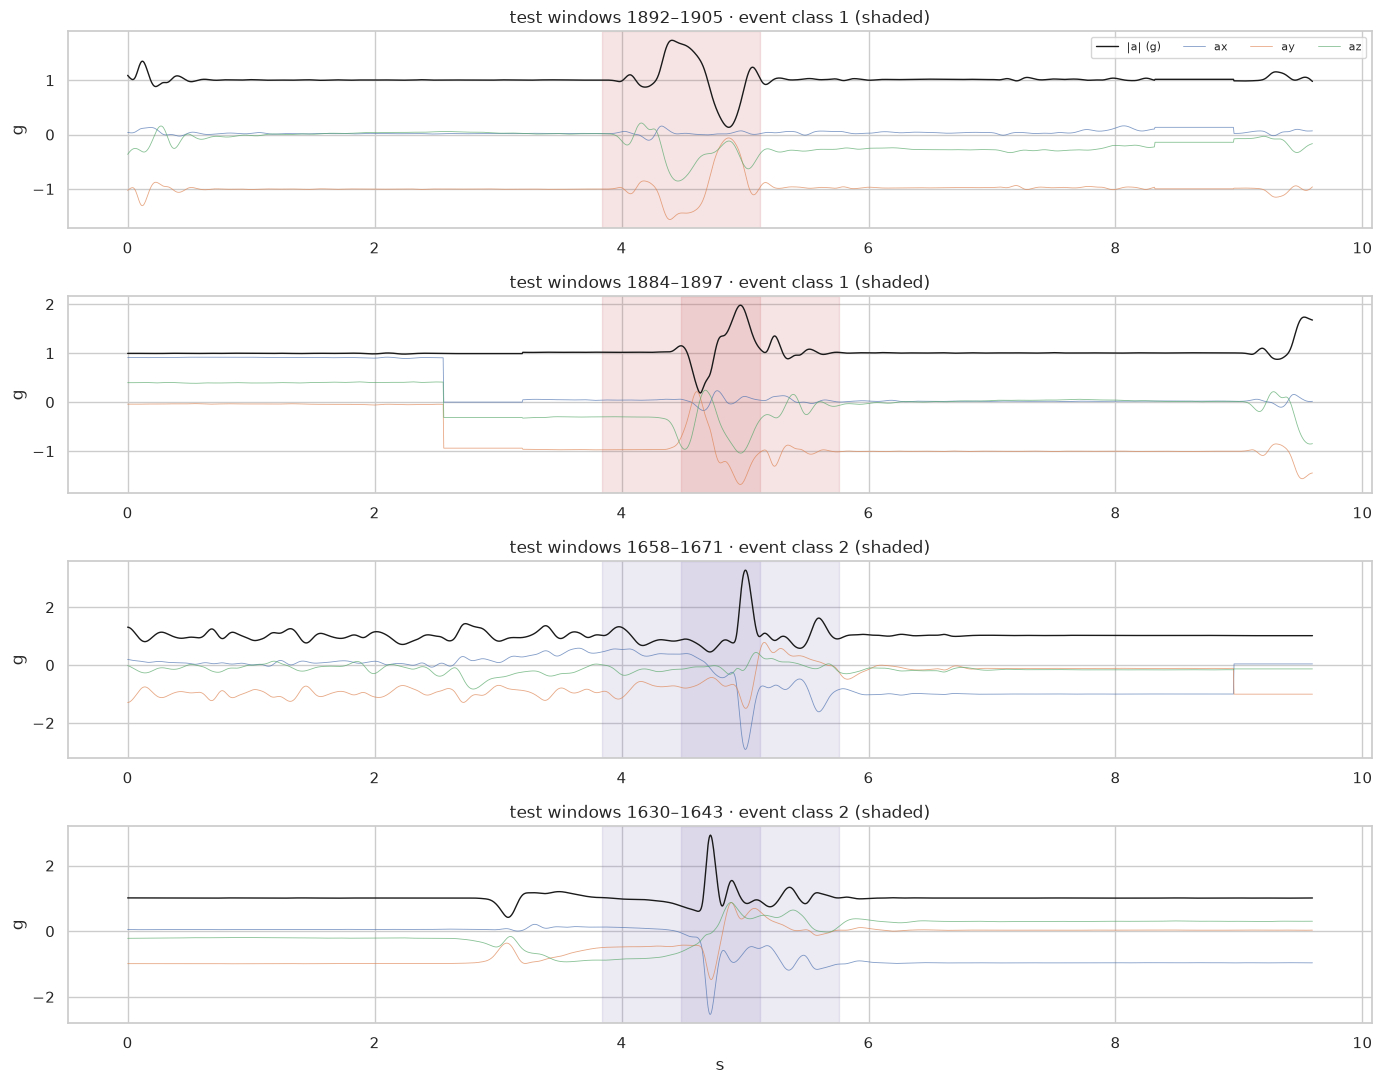

In [ ]:
def stitch(x, start, n, stride=128):
    seg = [np.asarray(x[start])] + [np.asarray(x[i, WINDOW - stride:]) for i in range(start + 1, start + n)]
    return np.concatenate(seg)

d = data["test"]
r = runs(d.y)
events = r[r["class"] > 0].reset_index(drop=True)
fig, axes = plt.subplots(4, 1, figsize=(14, 11))
for ax, (_, ev) in zip(axes, events.groupby("class").head(2).sort_values("class").iterrows()):
    s0 = max(int(ev.start) - 6, 0)
    n = 14
    sig = stitch(d.x, s0, n) / g_unit
    tt = np.arange(len(sig)) / SAMPLE_HZ
    ax.plot(tt, np.linalg.norm(sig[:, :3], axis=1), "k", lw=1, label="|a| (g)")
    for k in range(3):
        ax.plot(tt, sig[:, k], lw=0.6, alpha=0.7, label=CHANNELS[k])
    for j in range(n):
        c = d.y[s0 + j]
        if c:
            # window j covers [j*stride, j*stride+WINDOW); shade its fresh half
            ax.axvspan(j * 128 / SAMPLE_HZ, (j * 128 + WINDOW) / SAMPLE_HZ, color=f"C{c + 2}", alpha=0.15)
    ax.set_title(f"test windows {s0}–{s0 + n - 1} · event class {int(ev['class'])} (shaded)")
    ax.set_ylabel("g")
axes[0].legend(ncol=4, fontsize=8)
axes[-1].set_xlabel("s")
fig.tight_layout()

## 5. How separable are the classes with simple features?

              precision    recall  f1-score   support

           0      0.997     0.942     0.969     19463
           1      0.167     0.756     0.273       221
           2      0.636     0.974     0.770       549

    accuracy                          0.941     20233
   macro avg      0.600     0.891     0.671     20233
weighted avg      0.979     0.941     0.956     20233



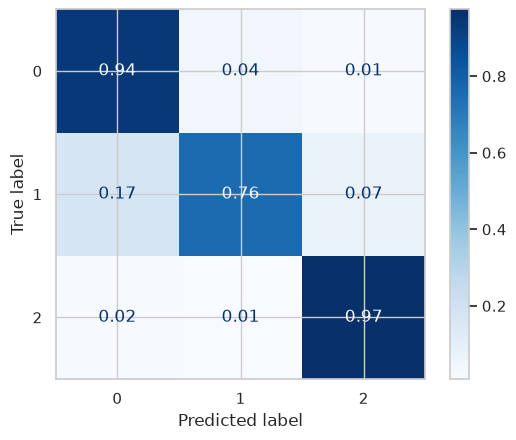

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

Xtr, ytr = feats["train"][cols], feats["train"]["class"]
Xva, yva = feats["val"][cols], feats["val"]["class"]
clf = HistGradientBoostingClassifier(class_weight="balanced", max_iter=300, random_state=0).fit(Xtr, ytr)
pred = clf.predict(Xva)
print(classification_report(yva, pred, digits=3))
ConfusionMatrixDisplay.from_predictions(yva, pred, normalize="true", values_format=".2f", cmap="Blues");

This is a quick check of how separable the classes are, not a model to keep: six summary numbers per window, no tuning. It tells
us how much signal plain magnitude features carry before we try sequence models (1D-CNN / GRU on the raw 256×6 windows).

## 6. Findings and open questions

**Dataset shape**
- 116,988 windows of **256 samples × 6 channels** (accel xyz and gyro xyz), 1.28 s each at 200 Hz. Split 77,871 train / 20,233 val / 18,884 test.
- Classes are about 96% / 1% / 3% (0 / 1 / 2), with almost the same mix in every split. `weights_3.txt` is listed in reverse class order.

**Units and preprocessing**
- Accel is scaled so that **1 g ≈ 0.231 units** (multiply by about 4.32 to get g). Gyro units are unknown.
- The signals are smooth, so they were probably low-pass filtered upstream.
- When test windows are stitched together you see flat stretches and sudden steps. These look like recording boundaries or padding, not real motion.

**What the classes probably mean** (inferred; the archive doesn't document it)

| | peak \|a\| | min \|a\| (free fall) | tilt change | reading |
|---|---|---|---|---|
| 0 | 1.1 g | 0.92 g | ~5° | background: normal activity, no event |
| 1 | 2.7 g | 0.16 g | ~15° | **impact, but the person stays upright** (jumps, stumbles, hard sit-downs, near-falls) |
| 2 | 3.2 g | 0.35 g | **~85°** | **fall**: impact, then the body ends up horizontal |

Class 2 is the one we want to detect as a fall. Class 1 is the hard negative: impacts that a simple threshold detector would mistake for falls.

**Temporal structure**
- Events last 1–3 windows inside long background stretches, with a `0 → event → 0` pattern.
- Test windows overlap by 50% (stride 0.64 s), so test can be replayed as a continuous stream. That's useful for evaluating streaming detection and for the Rerun visualization. Train and val have no overlap.

**Baseline**
- Six hand-made features with gradient boosting already reach **97% recall on falls (class 2)** on val, but precision is only 64%. Class 1 is the hard part (76% recall, 17% precision).
- Precision against background is what will matter on a real device, because every false alarm is noticed.

**Gaps for our goals**
1. **Fall type is not in this archive.** Classes 1 and 2 are coarse, with no F01–F15 codes and no subject IDs. To classify the *kind* of fall (forward / backward / lateral / from sitting / slip vs. trip), we need the **raw SisFall release**, whose filenames encode activity, subject and trial (e.g. `F05_SA01_R01.txt`).
2. **Possible subject leakage.** We can't tell whether the splits are by subject. If they aren't, val and test scores will be optimistic. The raw release would let us split by subject properly.
3. **Hardware mismatch.** SisFall is 200 Hz, waist-worn, y-axis vertical, and filtered. The LSM6DSOX sketch currently streams at 100 Hz. Before running a SisFall-trained model on our device, set the IMU to 208 Hz, mount it with the same axes, apply the same scaling, and low-pass filter the same way.

**Next steps**
- Get the raw SisFall release, for fall types, subject-wise splits and known units.
- Notebook 02: a sequence model (1D-CNN or GRU) on raw windows, compared against this feature baseline.
- Replay the stitched test stream and the live LSM6DSOX data in Rerun, with model probabilities plotted under the IMU curves.